# code_192 · A generator and a representation need a suite of tests

**Book:** section 36.5. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_36_GUIDE.md), [execution evidence](../CHAPTER_36_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_192).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Evaluation contracts identify the population, sampling unit, available information, score direction and decision consequences. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=7792;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 7792


<a id="generator-evaluation-suite"></a>
 ## Fit generators on source observations and evaluate independent observations
 Generate 800 source and 600 independent assessment sensor records. A 10% rare regime shifts future burden. Four visible features mix a high-variance irrelevant sensor, correlated severity readings and a small-scale regime marker; the response is future burden. Fit separate joint Gaussian means/covariances for each observed regime on source features plus response. Generate 800 synthetic records under source regime frequency. Compare an explicitly mode-dropped generator that samples only the common regime and a bootstrap copier of exact source records. The copier is a deliberate privacy stress control, not an acceptable release mechanism.

 Evaluate correlation-matrix error against independent records, rare-regime frequency and conditional response means. Fit the same Ridge recipe on each synthetic sample and score independent future burden. Standardized nearest-source distances use source-fitted scaling; exact copies are counted from the original joint feature/response rows. Low copy rate alone does not certify privacy, and these checks do not implement the paper's distributional precision/recall metric or image-based FID. Synthetic records never enter the independent assessment set.


,rare_fraction,correlation_error_Frobenius,overall_test_RMSE,rare_test_RMSE,exact_source_row_copy_fraction,median_standardized_nearest_source_distance,common_response_mean,rare_response_mean
Conditional Gaussian,0.09125,0.316191,3.026827,8.552114,0.0,0.295606,0.065311,14.712810
Mode dropped,0.00000,1.669488,4.944900,14.976423,0.0,0.278283,0.075039,NaN
Exact copier,0.09750,0.079453,2.922720,8.206833,1.0,0.000000,-0.082719,15.031364


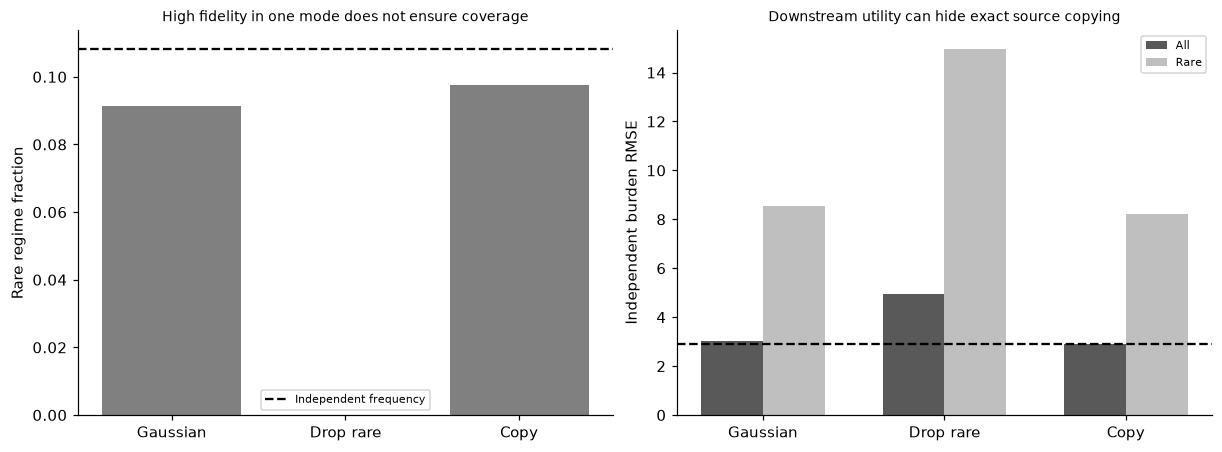

In [2]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
def real(n):
    regime=rng.binomial(1,.1,n);severity=rng.normal(size=n);x=np.c_[rng.normal(scale=6,size=n),severity,.8*severity+rng.normal(scale=.25,size=n),.1*regime+rng.normal(scale=.01,size=n)];y=2*severity+15*regime+rng.normal(scale=.4,size=n);return x,y,regime
xs,ys,rs=real(800);xf,yf,rf=real(600);joint=np.c_[xs,ys];stats={k:(joint[rs==k].mean(0),np.cov(joint[rs==k],rowvar=False)+1e-8*np.eye(5)) for k in [0,1]}
def generate(drop=False):
    r=np.zeros(800,dtype=int) if drop else rng.binomial(1,rs.mean(),800);out=np.empty((800,5))
    for k in [0,1]:out[r==k]=rng.multivariate_normal(*stats[k],size=np.sum(r==k))
    return out,r
fitted,rg=generate();dropped,rd=generate(True);ids=rng.integers(0,800,800);copies=joint[ids].copy();datasets={'Conditional Gaussian':(fitted,rg),'Mode dropped':(dropped,rd),'Exact copier':(copies,rs[ids])};scale=StandardScaler().fit(joint);nn=NearestNeighbors(n_neighbors=1).fit(scale.transform(joint));reference=np.c_[xf,yf];rows={};predictions={};source_model=Ridge(alpha=1).fit(xs,ys);source_rmse=float(np.sqrt(np.mean((source_model.predict(xf)-yf)**2)))
for name,(sample,regime) in datasets.items():
    model=Ridge(alpha=1).fit(sample[:,:4],sample[:,4]);p=model.predict(xf);predictions[name]=p;nearest=nn.kneighbors(scale.transform(sample),return_distance=True)[0][:,0];rare=rf==1
    rows[name]={'rare_fraction':float(regime.mean()),'correlation_error_Frobenius':float(np.linalg.norm(np.corrcoef(sample,rowvar=False)-np.corrcoef(reference,rowvar=False))),'overall_test_RMSE':float(np.sqrt(np.mean((p-yf)**2))),'rare_test_RMSE':float(np.sqrt(np.mean((p[rare]-yf[rare])**2))),'exact_source_row_copy_fraction':float(np.mean(np.min(np.max(abs(sample[:,None,:]-joint[None,:,:]),axis=2),axis=1)==0)),'median_standardized_nearest_source_distance':float(np.median(nearest)),'common_response_mean':float(sample[regime==0,4].mean()),'rare_response_mean':float(sample[regime==1,4].mean()) if (regime==1).any() else None};assert np.isfinite(p).all()
assert rows['Exact copier']['exact_source_row_copy_fraction']==1;assert rows['Mode dropped']['rare_fraction']==0;assert rows['Conditional Gaussian']['exact_source_row_copy_fraction']==0;RESULTS.update(source_records=800,final_records=600,synthetic_records_each=800,independent_rare_records=int(rf.sum()),independent_rare_fraction=float(rf.mean()),source_trained_test_RMSE=source_rmse,generator_scores=rows);display(pd.DataFrame(rows).T);fig,axes=plt.subplots(1,2,figsize=(11,4));names=list(rows);xx=np.arange(3);axes[0].bar(xx,[rows[k]['rare_fraction'] for k in names],color='.5');axes[0].axhline(rf.mean(),color='black',linestyle='--',label='Independent frequency');axes[0].set(xticks=xx,xticklabels=['Gaussian','Drop rare','Copy'],ylabel='Rare regime fraction',title='High fidelity in one mode does not ensure coverage');axes[0].legend(fontsize=7);axes[1].bar(xx-.17,[rows[k]['overall_test_RMSE'] for k in names],width=.34,color='.35',label='All');axes[1].bar(xx+.17,[rows[k]['rare_test_RMSE'] for k in names],width=.34,color='.75',label='Rare');axes[1].axhline(source_rmse,color='black',linestyle='--');axes[1].set(xticks=xx,xticklabels=['Gaussian','Drop rare','Copy'],ylabel='Independent burden RMSE',title='Downstream utility can hide exact source copying');axes[1].legend(fontsize=7);plt.show()


<a id="representation-reconstruction-and-probes"></a>
 ## A low-variance feature can carry the task information
 Fit three-component and four-component PCA to raw source sensor features only, without labels or assessment data. PCA intentionally sees raw measurement scales: the high-variance irrelevant sensor dominates reconstruction, whereas the small regime marker is predictive. Fit the same source-supervised Ridge probe in each representation and evaluate the same independent records. Report raw-unit reconstruction MSE separately from overall and rare-regime predictive RMSE; never add them. The four-component transform is an invertible reference, not learned compression. Probe quality depends on labels, hypothesis class and measurement scaling; this one probe does not characterize every possible use of a representation.


,reconstruction_MSE_raw_units,overall_probe_RMSE,rare_probe_RMSE,explained_variance_fraction
3,2.616801e-04,4.683044,13.480343,0.999975
4,9.389298e-31,2.896400,8.128664,1.000000


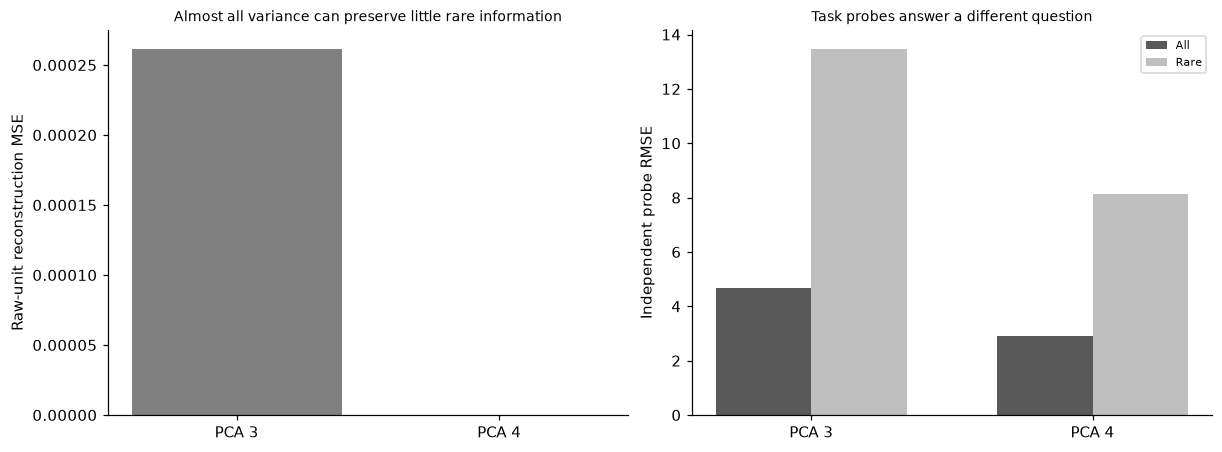

In [3]:
from sklearn.decomposition import PCA
repr_rows={}
for components in [3,4]:
    encoder=PCA(n_components=components).fit(xs);zs=encoder.transform(xs);zf=encoder.transform(xf);probe=Ridge(alpha=1).fit(zs,ys);p=probe.predict(zf);reconstruction=encoder.inverse_transform(zf);repr_rows[str(components)]={'reconstruction_MSE_raw_units':float(np.mean((reconstruction-xf)**2)),'overall_probe_RMSE':float(np.sqrt(np.mean((p-yf)**2))),'rare_probe_RMSE':float(np.sqrt(np.mean((p[rf==1]-yf[rf==1])**2))),'explained_variance_fraction':float(encoder.explained_variance_ratio_.sum())};assert encoder.n_samples_==800
assert repr_rows['4']['reconstruction_MSE_raw_units']<1e-20;assert repr_rows['3']['explained_variance_fraction']>.99;RESULTS.update(representation_scores=repr_rows,representation_source_labels_used_for_encoder=False,probe_source_labels_used=True);display(pd.DataFrame(repr_rows).T);fig,axes=plt.subplots(1,2,figsize=(11,4));xx=np.arange(2);axes[0].bar(xx,[repr_rows[k]['reconstruction_MSE_raw_units'] for k in ['3','4']],color='.5');axes[0].set(xticks=xx,xticklabels=['PCA 3','PCA 4'],ylabel='Raw-unit reconstruction MSE',title='Almost all variance can preserve little rare information');axes[1].bar(xx-.17,[repr_rows[k]['overall_probe_RMSE'] for k in ['3','4']],width=.34,color='.35',label='All');axes[1].bar(xx+.17,[repr_rows[k]['rare_probe_RMSE'] for k in ['3','4']],width=.34,color='.75',label='Rare');axes[1].set(xticks=xx,xticklabels=['PCA 3','PCA 4'],ylabel='Independent probe RMSE',title='Task probes answer a different question');axes[1].legend(fontsize=7);plt.show()


In [4]:
summary={'example_id':'code_192','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual conditional Gaussian sensor generator versus mode dropping and copying', 'rare regime coverage conditional means correlations and exact-copy diagnostics', 'actual train-on-synthetic test-on-independent-real regression', 'source-fitted PCA reconstruction and predictive probes with rare-slice scores'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual conditional Gaussian sensor generator versus mode dropping and copying", "rare regime coverage conditional means correlations and exact-copy diagnostics", "actual train-on-synthetic test-on-independent-real regression", "source-fitted PCA reconstruction and predictive probes with rare-slice scores"], "elapsed_seconds": 0.356, "example_id": "code_192", "hardware": "Darwin arm64 CPU", "results": {"final_records": 600, "generator_scores": {"Conditional Gaussian": {"common_response_mean": 0.06531051605580517, "correlation_error_Frobenius": 0.3161910125205074, "exact_source_row_copy_fraction": 0.0, "median_standardized_nearest_source_distance": 0.2956057693711669, "overall_test_RMSE": 3.02682654140255, "rare_fraction": 0.09125, "rare_response_mean": 14.712810074726532, "rare_test_RMSE": 8.552114451179035}, "Exact copier": {"common_response_mean": -0.08271941616135843, "correlation_error_Frobenius": 0.07945312567481197, "exact_source_